# 03 — Exploratory analysis (step 3)

Survey-weighted prevalence with design-based 95% CIs (`weight_mec`, strata `SDMVSTRA`, PSU `SDMVPSU`,
Taylor linearisation), crude risk ratios for the step 2 features, and a collinearity check.
All computation is in `hidden_risk.eda`; `python scripts/run_eda.py` writes the same tables and figures.

In [1]:
import pandas as pd
from IPython.display import Image, display
from hidden_risk.config import DATA_PROCESSED, REPORT_FIGURES
from hidden_risk.eda import analysis_frame, correlation_pairs, risk_ratio_table, weighted_prevalence_table
from hidden_risk.cohort import SCREEN_CUTOFF
from hidden_risk.models import FEATURE_SETS

pd.set_option("display.precision", 2)
df = analysis_frame()
trend = pd.read_parquet(DATA_PROCESSED / "nhanes_2021_2023_phq9.parquet")

## Weighted prevalence of suicidal ideation (95% CI)

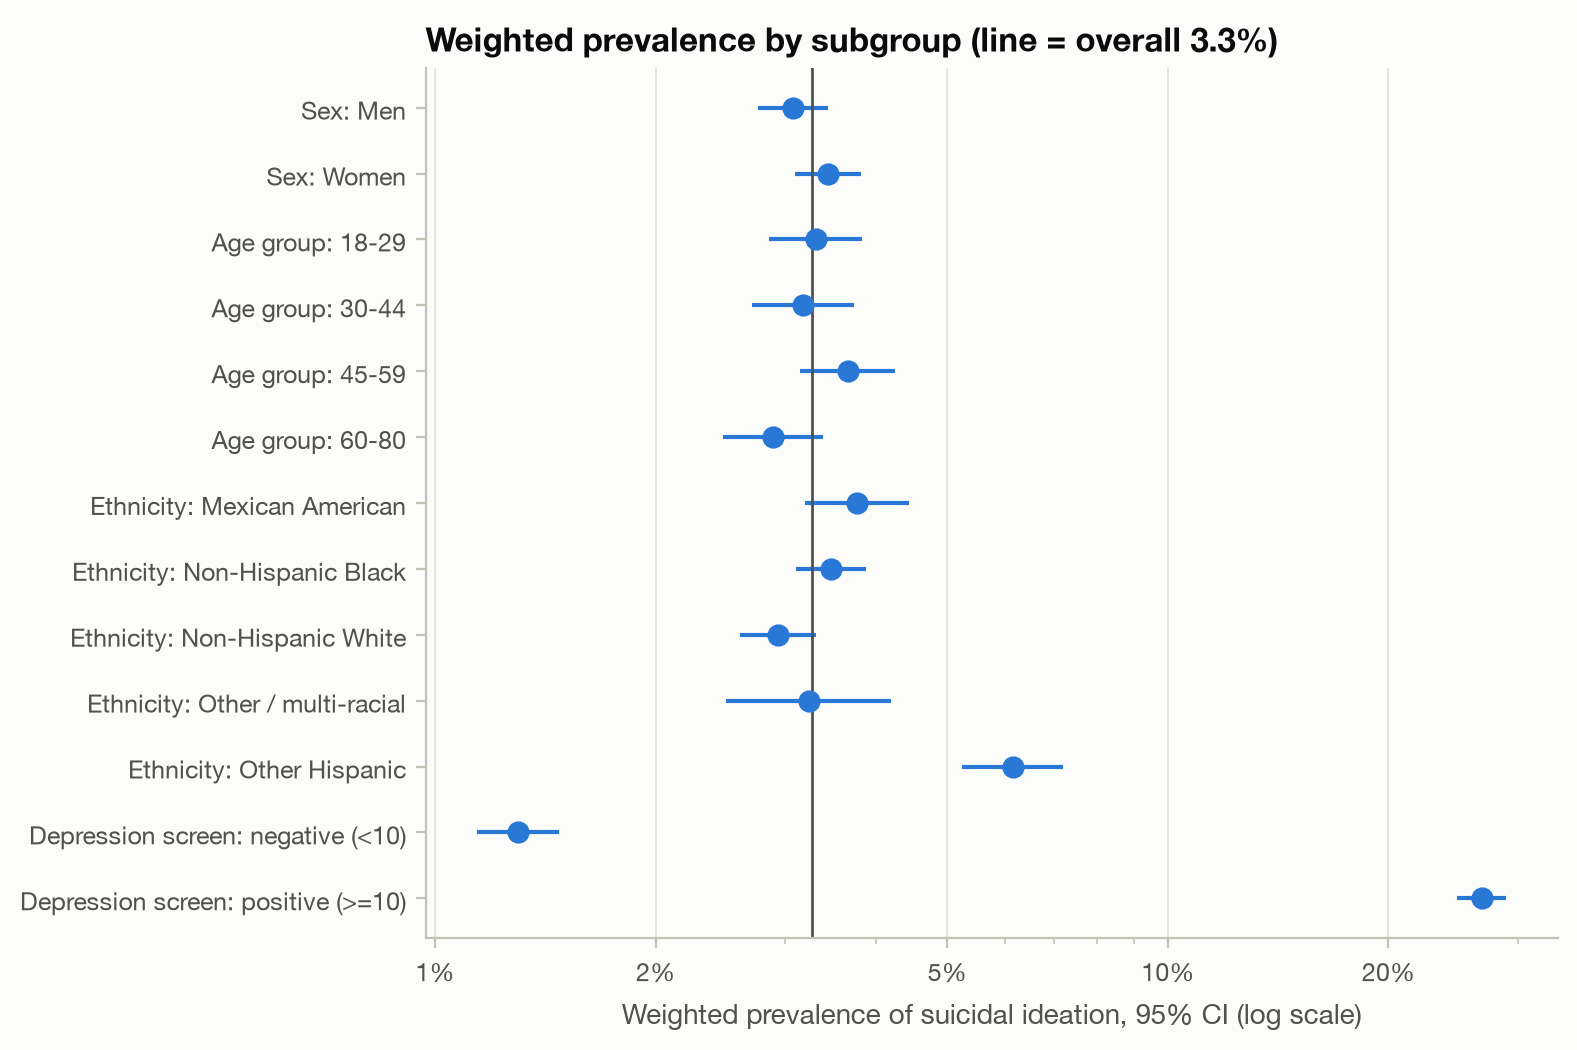

,group,level,n,cases,pct,ci_low,ci_high
0,Overall,2005-2018,36259,1366,3.26,3.00,3.55
1,Cycle,2005-2006,4799,162,2.88,2.36,3.51
2,Cycle,2007-2008,5415,246,3.39,2.73,4.21
3,Cycle,2009-2010,5546,202,3.19,2.55,3.99
4,Cycle,2011-2012,4925,190,3.24,2.42,4.33
5,Cycle,2013-2014,5372,183,3.35,2.70,4.14
6,Cycle,2015-2016,5134,192,3.35,2.49,4.50
7,Cycle,2017-2018,5068,191,3.40,2.87,4.02
8,Cycle,2021-2023 (trend check),5455,292,5.31,4.29,6.55
9,Sex,Men,17812,618,3.08,2.76,3.44


In [2]:
prev = weighted_prevalence_table(df, trend)
display(Image(REPORT_FIGURES / "06_weighted_prevalence_ci.png", width=700))
prev[["group", "level", "n", "cases", "pct", "ci_low", "ci_high"]]

## Crude risk ratios, including the step 2 medication classes

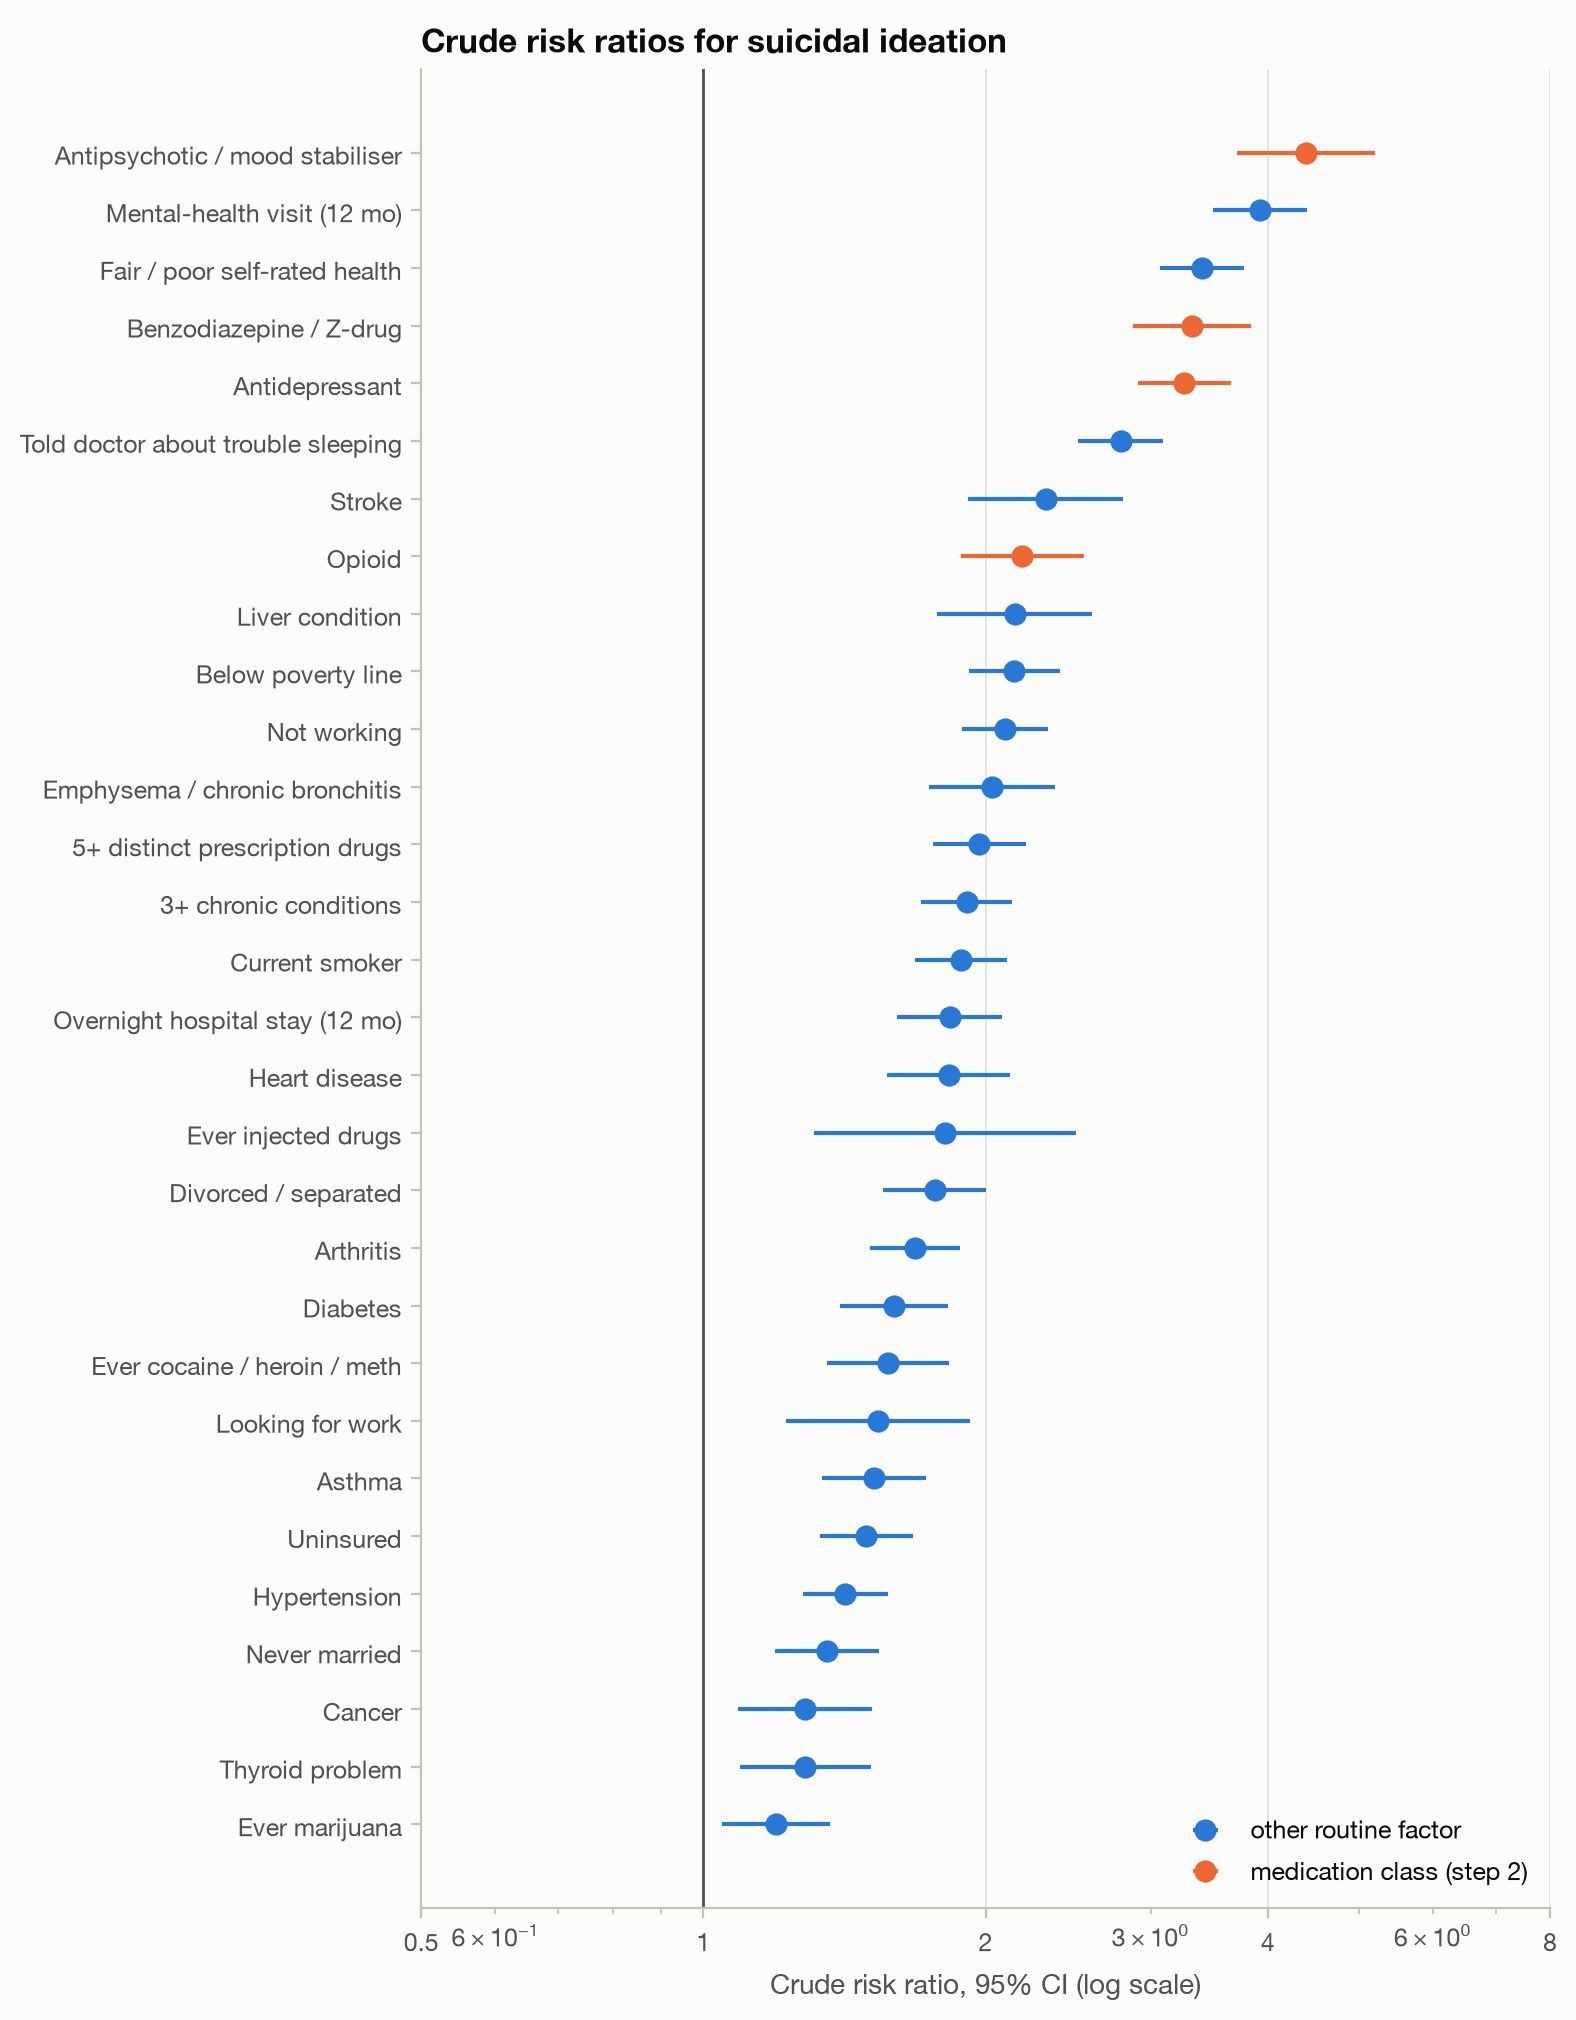

,factor,n_exposed,cases_exposed,risk_exposed_pct,risk_unexposed_pct,rr,ci_low,ci_high
0,Antipsychotic / mood stabiliser,813,125,15.38,3.50,4.39,3.71,5.21
1,Mental-health visit (12 mo),2941,351,11.93,3.04,3.92,3.50,4.40
2,Fair / poor self-rated health,8479,695,8.20,2.41,3.40,3.07,3.77
3,Benzodiazepine / Z-drug,1713,193,11.27,3.39,3.32,2.87,3.83
4,Antidepressant,3736,372,9.96,3.05,3.26,2.91,3.65
5,Told doctor about trouble sleeping,9016,655,7.26,2.61,2.79,2.51,3.09
6,Stroke,1284,106,8.26,3.56,2.32,1.92,2.81
7,Opioid,2365,181,7.65,3.50,2.19,1.88,2.55
8,Liver condition,1395,107,7.67,3.57,2.15,1.77,2.60
9,Below poverty line,7231,463,6.40,2.98,2.15,1.92,2.40


In [3]:
rr = risk_ratio_table(df)
display(Image(REPORT_FIGURES / "07_risk_ratios_step2_features.png", width=700))
rr[["factor", "n_exposed", "cases_exposed", "risk_exposed_pct", "risk_unexposed_pct", "rr", "ci_low", "ci_high"]]

Among screen-negative adults (PHQ-9 < 10) only:

In [4]:
risk_ratio_table(df, restrict=df["phq9_score"] < SCREEN_CUTOFF)[["factor", "cases_exposed", "rr", "ci_low", "ci_high"]].head(12)

,factor,cases_exposed,rr,ci_low,ci_high
0,Antipsychotic / mood stabiliser,25,3.33,2.25,4.94
1,Mental-health visit (12 mo),71,2.61,2.04,3.35
2,Antidepressant,87,2.49,1.98,3.14
3,Fair / poor self-rated health,173,2.29,1.91,2.76
4,Benzodiazepine / Z-drug,32,1.98,1.39,2.82
5,Ever injected drugs,11,1.93,1.06,3.49
6,Told doctor about trouble sleeping,161,1.86,1.54,2.25
7,Liver condition,28,1.82,1.25,2.65
8,Below poverty line,132,1.74,1.42,2.13
9,Not working,247,1.73,1.44,2.06


## Collinearity among the routine-data model features (Spearman)

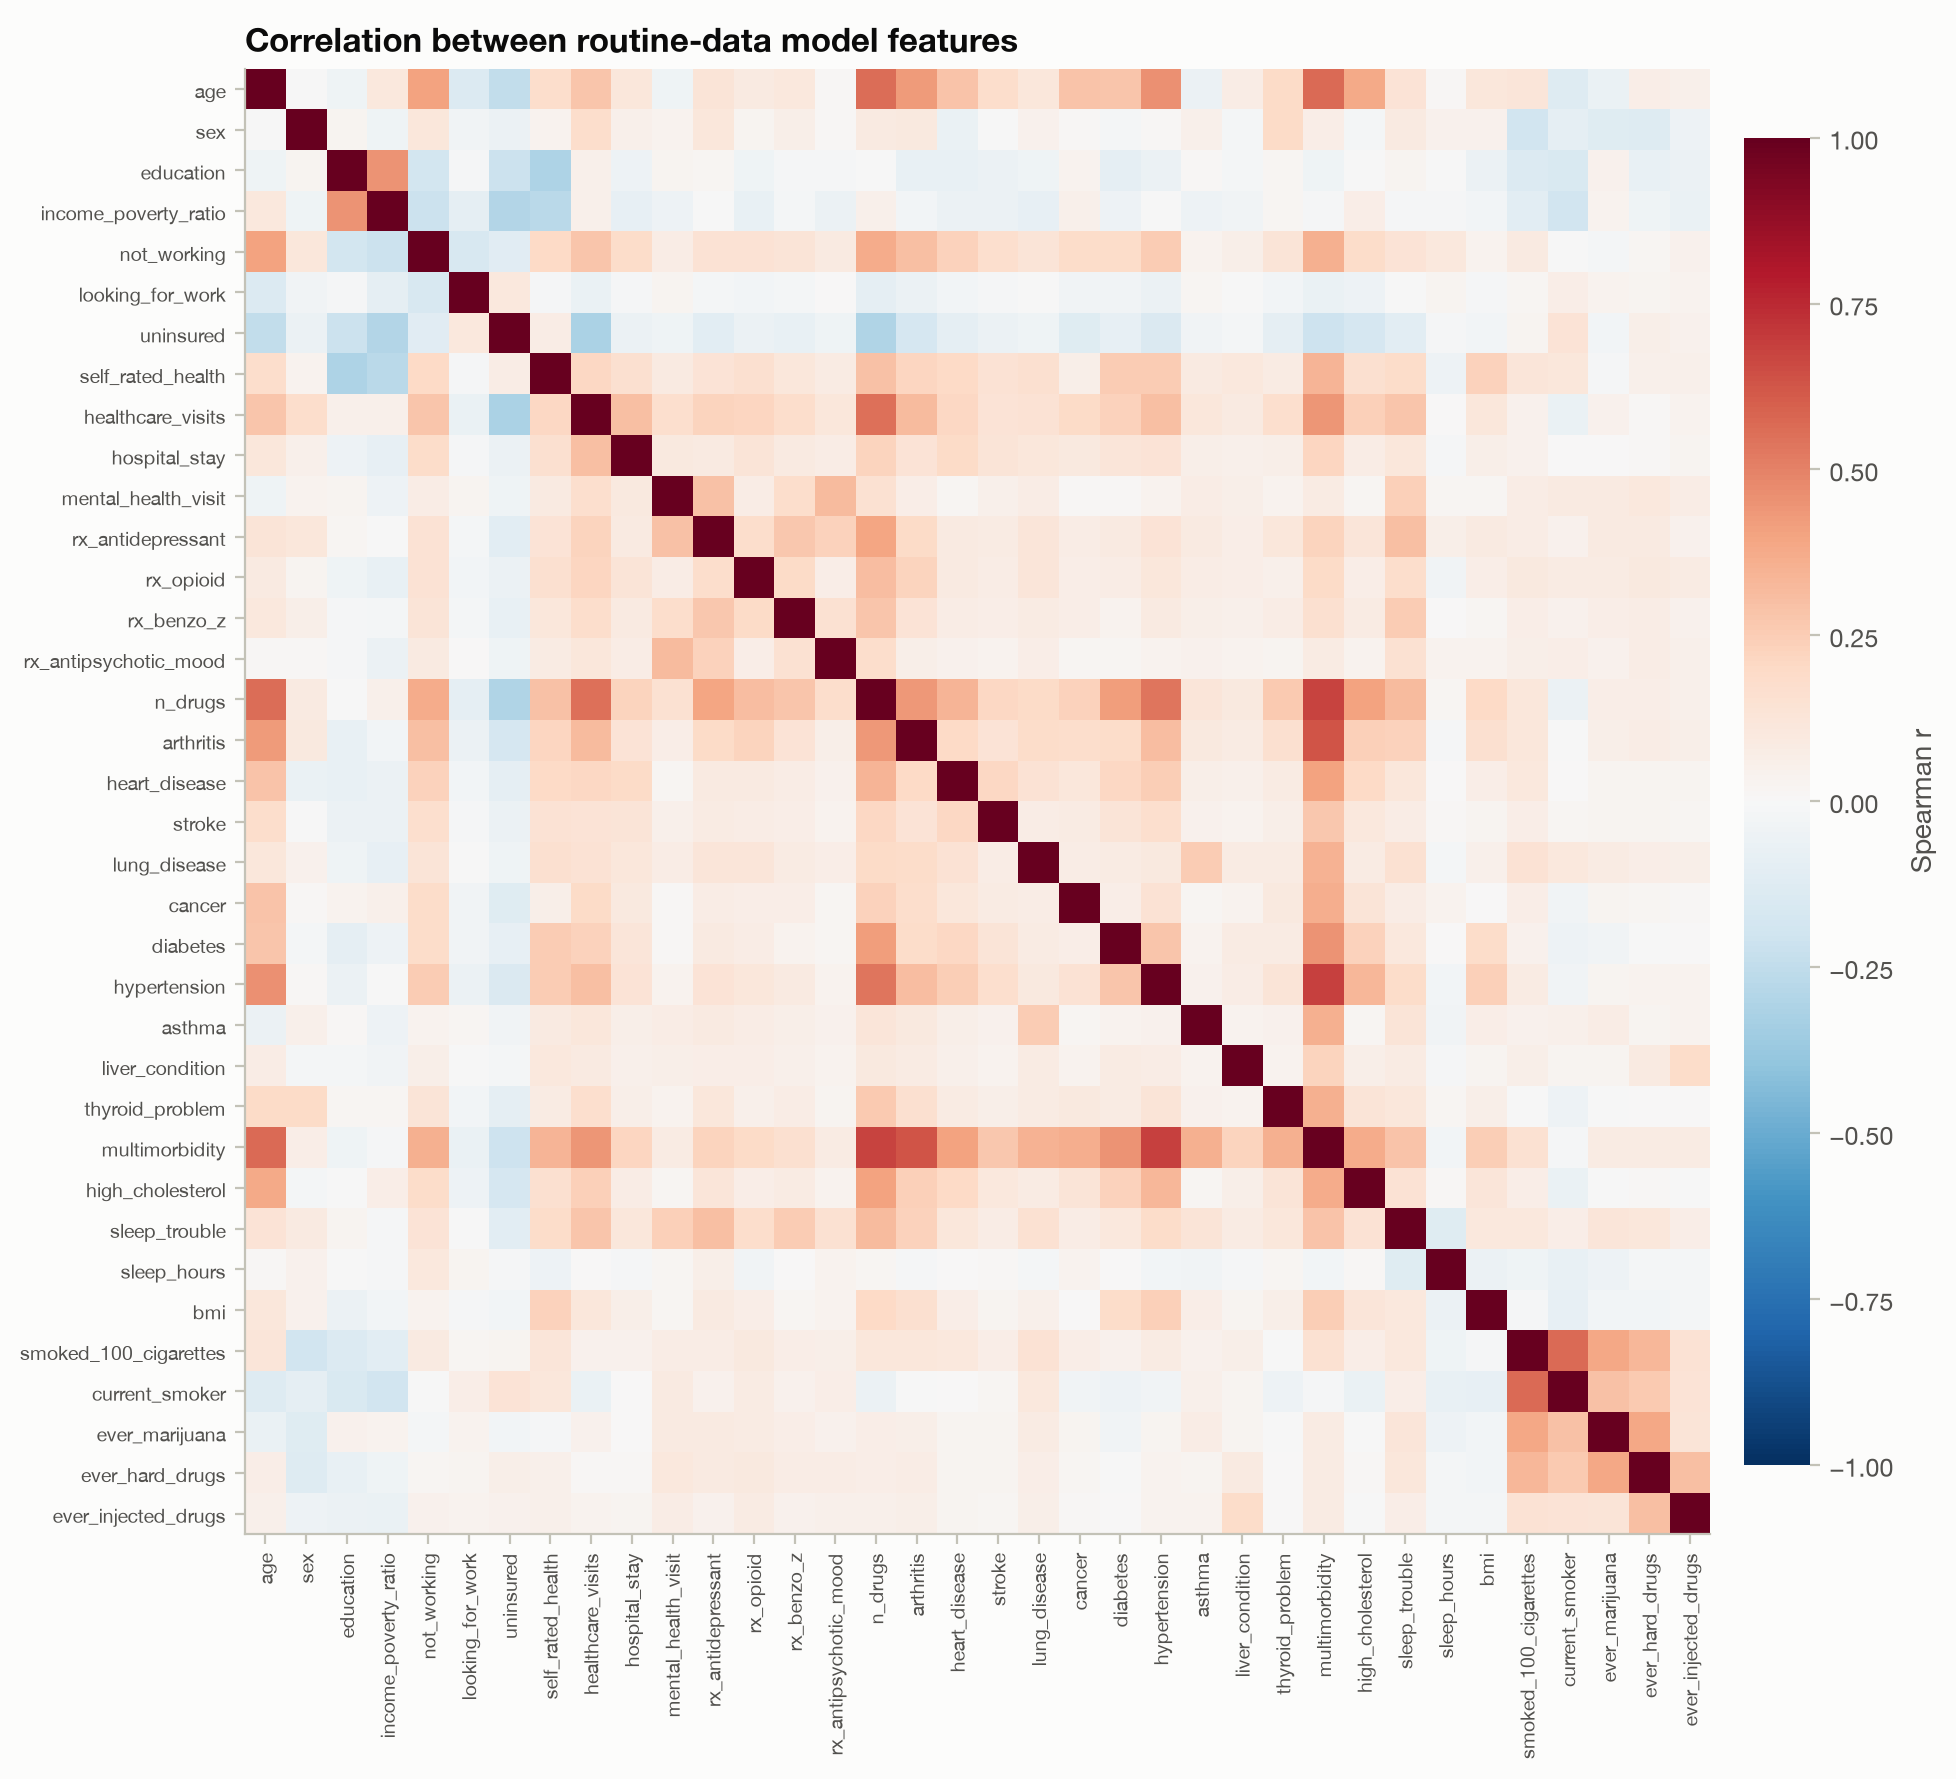

               feature_1            feature_2  spearman_r  abs_r  collinear
49   mental_health_visit    rx_antidepressant        0.29   0.29      False
695  mental_health_visit  mental_health_visit         NaN    NaN      False
706    rx_antidepressant  mental_health_visit         NaN    NaN      False
707    rx_antidepressant    rx_antidepressant         NaN    NaN      False


,feature_1,feature_2,spearman_r,abs_r,collinear
0,hypertension,multimorbidity,0.69,0.69,True
1,n_drugs,multimorbidity,0.68,0.68,True
2,arthritis,multimorbidity,0.63,0.63,True
3,age,multimorbidity,0.57,0.57,True
4,smoked_100_cigarettes,current_smoker,0.56,0.56,True
5,age,n_drugs,0.56,0.56,True
6,healthcare_visits,n_drugs,0.55,0.55,True
7,n_drugs,hypertension,0.53,0.53,True


In [5]:
pairs, corr = correlation_pairs(df, [c for c in FEATURE_SETS["routine"] if c not in ("ethnicity", "marital_status")])
display(Image(REPORT_FIGURES / "08_feature_correlation.png", width=700))
print(pairs[(pairs[["feature_1", "feature_2"]].isin(["rx_antidepressant", "mental_health_visit"])).all(axis=1)])
pairs[pairs.collinear]